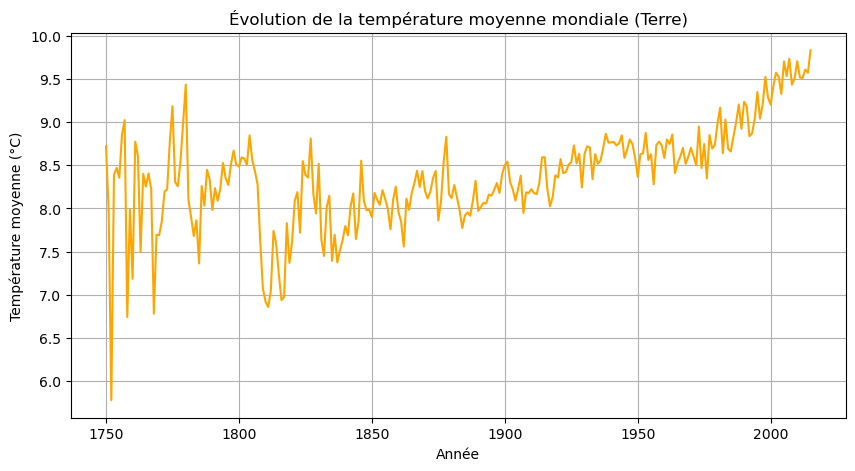

Coefficient de corrélation = 0.622
Pays sans continent (à ajouter au mapping) : ['Africa', 'American Samoa', 'Andorra', 'Anguilla', 'Antigua And Barbuda', 'Armenia', 'Aruba', 'Asia', 'Azerbaijan', 'Bahamas', 'Bahrain', 'Baker Island', 'Barbados', 'Belize', 'Bhutan', 'Bonaire, Saint Eustatius And Saba', 'British Virgin Islands', 'Burma', 'Cambodia', 'Cape Verde', 'Cayman Islands', 'Christmas Island', 'Comoros', 'Costa Rica', 'Cuba', 'Curaçao', 'Cyprus', 'Denmark (Europe)', 'Dominica', 'Dominican Republic', 'El Salvador', 'Equatorial Guinea', 'Eritrea', 'Europe', 'Falkland Islands (Islas Malvinas)', 'Faroe Islands', 'Federated States Of Micronesia', 'Fiji', 'France (Europe)', 'French Guiana', 'French Polynesia', 'French Southern And Antarctic Lands', 'Gambia', 'Gaza Strip', 'Georgia', 'Greenland', 'Grenada', 'Guadeloupe', 'Guam', 'Guatemala']


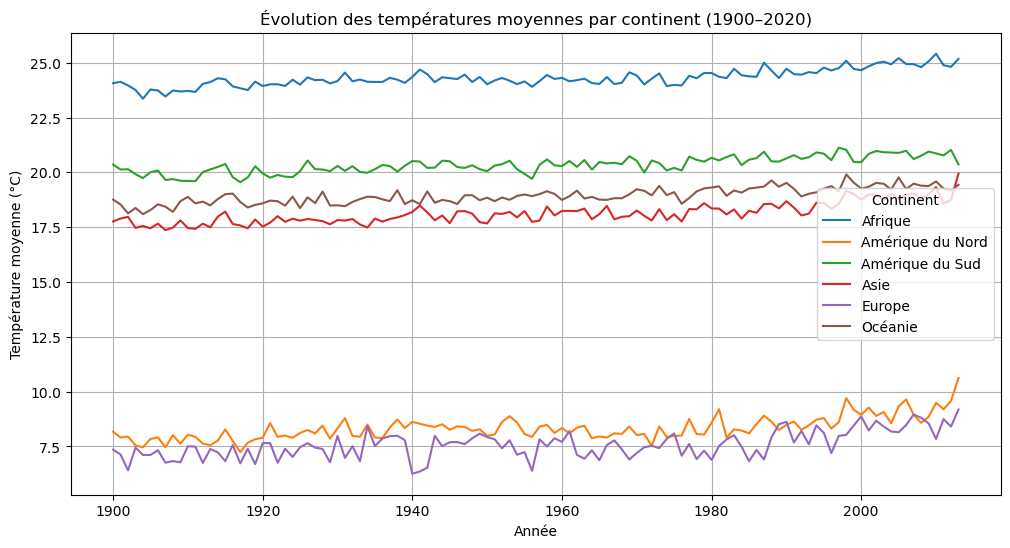

Pente (a) : 0.004731692034283844
Ordonnée à l'origine (b) : -0.5380731373958287
Coefficient de détermination R² : 0.387


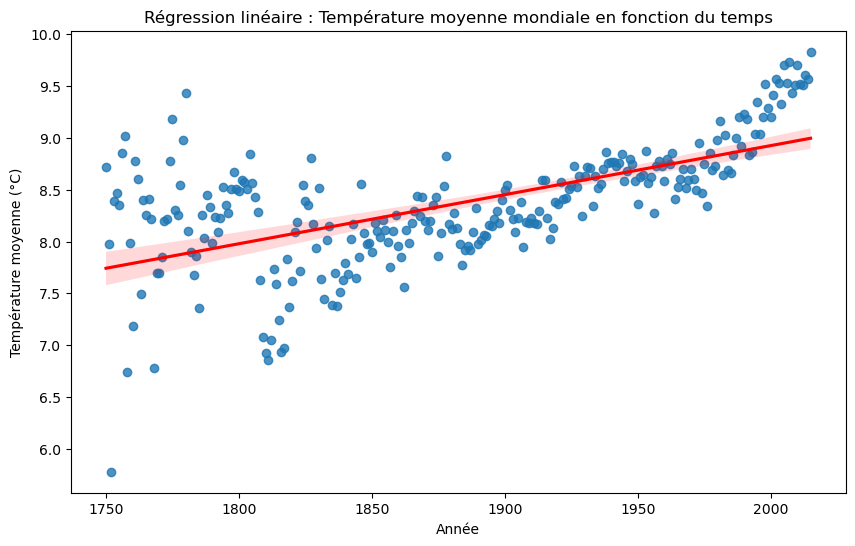

In [8]:
import pandas as pd 
import matplotlib.pyplot as plt
import numpy as np 
import seaborn as sns

df_global = pd.read_csv("C:/Users/Lydia/Documents/GlobalTemperatures.csv")
f_country = pd.read_csv("C:/Users/Lydia/Documents/GlobalLandTemperaturesByCountry.csv")

df_global.isna().sum()
df_global = df_global.dropna(subset=['LandAverageTemperature'])


df_global['Year'] = pd.to_datetime(df_global['dt']).dt.year
df_global[['dt', 'Year']].head()

df_yearly = df_global.groupby('Year')['LandAverageTemperature'].mean().reset_index()
df_yearly.head()

plt.figure(figsize=(10,5))
plt.plot(df_yearly['Year'], df_yearly['LandAverageTemperature'], color='orange')
plt.title("Évolution de la température moyenne mondiale (Terre)")
plt.xlabel("Année")
plt.ylabel("Température moyenne (°C)")
plt.grid(True)
plt.show()

corr = df_yearly['Year'].corr(df_yearly['LandAverageTemperature'])
print("Coefficient de corrélation =", round(corr, 3))

df_country = pd.read_csv("C:/Users/Lydia/Documents/GlobalLandTemperaturesByCountry.csv")
df_country.head()

df_country = df_country.dropna(subset=['AverageTemperature'])
df_country['Year'] = pd.to_datetime(df_country['dt']).dt.year

df_country = df_country[df_country['Year'] >= 1900]

continent_mapping = {
    # Afrique
    'Algeria': 'Afrique', 'Angola': 'Afrique', 'Benin': 'Afrique', 'Botswana': 'Afrique',
    'Burkina Faso': 'Afrique', 'Burundi': 'Afrique', 'Cameroon': 'Afrique', 'Central African Republic': 'Afrique',
    'Chad': 'Afrique', 'Congo': 'Afrique', 'Congo (Democratic Republic Of The)': 'Afrique',
    'Côte D\'Ivoire': 'Afrique', 'Djibouti': 'Afrique', 'Egypt': 'Afrique', 'Ethiopia': 'Afrique',
    'Gabon': 'Afrique', 'Ghana': 'Afrique', 'Guinea': 'Afrique', 'Kenya': 'Afrique', 'Libya': 'Afrique',
    'Madagascar': 'Afrique', 'Mali': 'Afrique', 'Mauritania': 'Afrique', 'Morocco': 'Afrique',
    'Mozambique': 'Afrique', 'Niger': 'Afrique', 'Nigeria': 'Afrique', 'Rwanda': 'Afrique',
    'Senegal': 'Afrique', 'Somalia': 'Afrique', 'South Africa': 'Afrique', 'South Sudan': 'Afrique',
    'Sudan': 'Afrique', 'Tanzania': 'Afrique', 'Togo': 'Afrique', 'Tunisia': 'Afrique',
    'Uganda': 'Afrique', 'Zambia': 'Afrique', 'Zimbabwe': 'Afrique',
    
    # Amérique du Nord
    'Canada': 'Amérique du Nord', 'United States': 'Amérique du Nord', 'Mexico': 'Amérique du Nord',
    
    # Amérique du Sud
    'Argentina': 'Amérique du Sud', 'Bolivia': 'Amérique du Sud', 'Brazil': 'Amérique du Sud',
    'Chile': 'Amérique du Sud', 'Colombia': 'Amérique du Sud', 'Ecuador': 'Amérique du Sud',
    'Paraguay': 'Amérique du Sud', 'Peru': 'Amérique du Sud', 'Uruguay': 'Amérique du Sud',
    'Venezuela': 'Amérique du Sud',
    
    # Asie
    'Afghanistan': 'Asie', 'Bangladesh': 'Asie', 'China': 'Asie', 'India': 'Asie', 'Indonesia': 'Asie',
    'Iran': 'Asie', 'Iraq': 'Asie', 'Japan': 'Asie', 'Kazakhstan': 'Asie', 'Malaysia': 'Asie',
    'Mongolia': 'Asie', 'Myanmar': 'Asie', 'Nepal': 'Asie', 'Pakistan': 'Asie', 'Philippines': 'Asie',
    'Saudi Arabia': 'Asie', 'South Korea': 'Asie', 'Thailand': 'Asie', 'Turkey': 'Asie',
    'Uzbekistan': 'Asie', 'Vietnam': 'Asie', 'Yemen': 'Asie',
    
    # Europe
    'Albania': 'Europe', 'Austria': 'Europe', 'Belarus': 'Europe', 'Belgium': 'Europe',
    'Bosnia And Herzegovina': 'Europe', 'Bulgaria': 'Europe', 'Croatia': 'Europe', 'Czech Republic': 'Europe',
    'Denmark': 'Europe', 'Estonia': 'Europe', 'Finland': 'Europe', 'France': 'Europe', 'Germany': 'Europe',
    'Greece': 'Europe', 'Hungary': 'Europe', 'Ireland': 'Europe', 'Italy': 'Europe', 'Latvia': 'Europe',
    'Lithuania': 'Europe', 'Netherlands': 'Europe', 'Norway': 'Europe', 'Poland': 'Europe',
    'Portugal': 'Europe', 'Romania': 'Europe', 'Russia': 'Europe', 'Serbia': 'Europe', 'Slovakia': 'Europe',
    'Spain': 'Europe', 'Sweden': 'Europe', 'Switzerland': 'Europe', 'Ukraine': 'Europe',
    'United Kingdom': 'Europe',
    
    # Océanie
    'Australia': 'Océanie', 'New Zealand': 'Océanie', 'Papua New Guinea': 'Océanie'
    
}
df_country['Continent'] = df_country['Country'].map(continent_mapping)
missing = sorted(df_country.loc[df_country['Continent'].isna(), 'Country'].unique())
print("Pays sans continent (à ajouter au mapping) :", missing[:50])

df_continent = (
    df_country.dropna(subset=['Continent'])      # <— important
              .groupby(['Year', 'Continent'])['AverageTemperature']
              .mean()
              .reset_index()
              .sort_values(['Continent','Year'])
    
)
plt.figure(figsize=(12,6))
sns.lineplot(data=df_continent, x='Year', y='AverageTemperature', hue='Continent')
plt.title("Évolution des températures moyennes par continent (1900–2020)")
plt.xlabel("Année")
plt.ylabel("Température moyenne (°C)")
plt.legend(title="Continent")
plt.grid(True)
plt.show()

from sklearn.linear_model import LinearRegression
X = df_yearly[['Year']] 
y = df_yearly['LandAverageTemperature']
model = LinearRegression()
model.fit(X, y)

a = model.coef_[0]     
b = model.intercept_    
print("Pente (a) :", a)
print("Ordonnée à l'origine (b) :", b)

r2 = model.score(X, y)
print("Coefficient de détermination R² :", round(r2, 3))

plt.figure(figsize=(10,6))
sns.regplot(x='Year', y='LandAverageTemperature', data=df_yearly, line_kws={'color':'red'})
plt.title("Régression linéaire : Température moyenne mondiale en fonction du temps")
plt.xlabel("Année")
plt.ylabel("Température moyenne (°C)")
plt.show()


